<a href="https://colab.research.google.com/github/serennnn4/Fundamentos-Machine-Learning/blob/main/PA2_3018.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Caso: Organización del laboratorio LIBIPMET**


---


### Fundamentos de Machine Learning | Proceso de Aprendizaje II
##### Por: María Fernanda León Catalán


**Problemática:** Se busca entrenar un modelo no supervisado de clustering (K-Means) para poder agrupar compuestos químicos desde las proposiciones fisicoquímicas, determinando el número óptimo de grupos. Una vez se obtenga dicho modelo, se exportará para su uso.

Dicho trabajo se presentará a través del proceso analítico EDA.


---




### **Primera fase: Recolección de datos**
##### Se importarán las librerías y después se cargará el dataset.



In [215]:
##Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg ##
import seaborn as sns
import missingno as msno


from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib


In [201]:
##Carga de dataset

url="https://raw.githubusercontent.com/inefable12/inteligencia_molecular/refs/heads/main/SESION_2/dataset_PA2.csv"
df=pd.read_csv(url)


##Resumen del dataset
df.head().style.set_caption("Resumen")

,smiles,validacion,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
0,C(CCl)Cl,0,4,4,1.464000,98.960000,74.775745
1,C(CO)O,0,4,6,-1.029000,62.068000,40.460000
2,CC(=O)C,0,4,6,0.595300,58.080000,17.070000
3,CCCCO,0,5,10,0.778800,74.123000,20.230000
4,Cl,0,1,1,0.421800,36.461000,74.775745




---


### **Segunda fase: Limpieza de datos**
##### Se evaluará la integridad y se realizará la limpieza respectiva.


In [202]:
#Revisión Integridad
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   smiles          140 non-null    object 
 1   validacion      140 non-null    int64  
 2   NumAtomPesados  140 non-null    int64  
 3   h_implicitos    140 non-null    int64  
 4   coef_de_part    140 non-null    float64
 5   MM              140 non-null    float64
 6   TPSA            140 non-null    float64
dtypes: float64(3), int64(3), object(1)
memory usage: 7.8+ KB


#####Conclusión: Con la ejecución del código, se evidencia que contamos con con 140 moléculas para trabajar en los 7 atributos(columnas). Además, no contamos con datos nulos.


In [203]:
# La columna validacion con valor 0, significa que la representación "SMILES" es
# correcta.

#Revisión columna "Validación" = 0
(df['validacion'] == 0).sum()



np.int64(140)

#####Conclusión: Se verificó que los 140 registros cumplen la condición de validación == 0, por lo que no fue necesario descartar algo.



---
### **Preprocesamiento**


---




In [204]:
# Separamos las columnnas de identificación (Smiles, Validacion)
# de columnas numéricas (NumAtomPesados, h_implicitos,
#coef_de_part, MM, TPSA) que se usarán para el clustering.

df_id=df[['smiles','validacion']]
df_numerica=df[['NumAtomPesados','h_implicitos','coef_de_part','MM','TPSA']]

df_numerica.head().style.set_caption("ResumenSeparacion")

,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
0,4,4,1.464000,98.960000,74.775745
1,4,6,-1.029000,62.068000,40.460000
2,4,6,0.595300,58.080000,17.070000
3,5,10,0.778800,74.123000,20.230000
4,1,1,0.421800,36.461000,74.775745


In [205]:
# Se eliminará algún atributo con correlación de Pearson > 0.9 de ser necesario.

df_numerica.corr(method='pearson')

,NumAtomPesados,h_implicitos,coef_de_part,MM,TPSA
NumAtomPesados,1.000000,0.878918,0.647949,0.983952,0.616025
h_implicitos,0.878918,1.000000,0.785084,0.862607,0.370809
coef_de_part,0.647949,0.785084,1.000000,0.644347,-0.060621
MM,0.983952,0.862607,0.644347,1.000000,0.617019
TPSA,0.616025,0.370809,-0.060621,0.617019,1.000000


In [206]:
# Al encontrar una correlación >0.9 entre:
# NumAtomPesados y MM, decidimos mantener MM
# ya que cuenta con mayor información
#sobre el tamaño y la masa de cada molécula.

df_numerica=df_numerica.drop(columns=['NumAtomPesados'])

#Visualización del descarte de columna.
df_numerica.head().style.set_caption("Resumen Descarte de Columna NumAtomPesado")

,h_implicitos,coef_de_part,MM,TPSA
0,4,1.464000,98.960000,74.775745
1,6,-1.029000,62.068000,40.460000
2,6,0.595300,58.080000,17.070000
3,10,0.778800,74.123000,20.230000
4,1,0.421800,36.461000,74.775745


In [207]:
# Aplicaremos la estandarización/normalización a las variables numéricas.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_numerica)


#Visualización
df_scaled = pd.DataFrame(X_scaled, columns=df_numerica.columns)
df_scaled.head().style.set_caption("Resumen Estandarización")

,h_implicitos,coef_de_part,MM,TPSA
0,-1.010611,-0.732542,-1.121159,-0.088494
1,-0.923917,-1.398574,-1.276287,-0.666812
2,-0.923917,-0.964625,-1.293056,-1.061000
3,-0.750528,-0.915601,-1.225597,-1.007745
4,-1.140653,-1.010977,-1.383963,-0.088494




---


### **Tercera fase: Implementación de modelo**
##### Selección de K de acuerdo a la inercia y cohesión

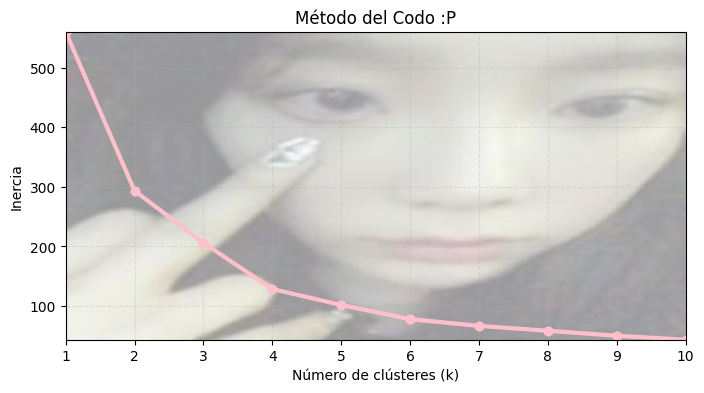

In [235]:
#Rango de grupos para evaluar la Inercia.
inercia = []
k_value_elbow= range(1,11)


for k in k_value_elbow:
  kmeans = KMeans(n_clusters=k, random_state=42,n_init=10)
  kmeans.fit(df_scaled)
  inercia.append(kmeans.inertia_)

#Visualización del Diagrama del Codo

img = mpimg.imread('taeyeon.jpg')
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(img, extent=[1, 10, min(inercia), max(inercia)],
          aspect='auto', alpha=0.4, zorder=1)

ax.plot(k_value_elbow, inercia, marker='o', color='pink', zorder=2)


ax.plot(k_value_elbow, inercia, marker='o', color='pink', linewidth=3, zorder=2)

ax.set_title('Método del Codo :P')
ax.set_xlabel('Número de clústeres (k)')
ax.set_ylabel('Inercia')
ax.grid(True, linestyle='--', alpha=0.3, zorder=3)

plt.show()



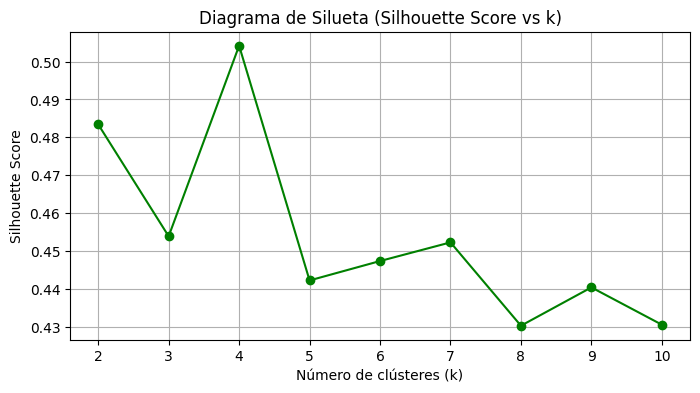

In [209]:
#Rango de grupos para evaluar la Cohesión y Separación.
silueta = []
k_value_sil= range(2,11)


for k in k_value_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, etiquetas)
    silueta.append(score)

#Visualización del Diagrama de la Silueta
plt.figure(figsize=(8, 4))
plt.plot(k_value_sil, silueta, marker='o', color='green')
plt.title('Diagrama de Silueta (Silhouette Score vs k)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

####**Conclusión:** Se seleccionó K = 4 como el número óptimo de clústeres debido a la concordancia entre ambos criterios.

####En el diagrama del codo representa el punto de inflexión donde la inercia reduce su tasa de disminución; mientras tanto, en el análisis de silueta, K = 4 maximiza el coeficiente medio de silueta, garantizando clústeres compactos y bien diferenciados entre sí,

In [210]:
#Ajuste y entrenamiento final Modelo

#Ajuste con K=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
etiquetas = kmeans_final.fit_predict(df_scaled)

df_resultado = df_numerica.copy()
df_resultado['cluster'] = etiquetas

#Total de moléculas
print(df_resultado['cluster'].value_counts())


cluster
3    72
2    35
0    18
1    15
Name: count, dtype: int64




---


### **Cuarta Fase: Análisis, Resumen y Conclusiones**
##### Conclusiones sobre el tipo de moléculas agrupadas.

In [211]:
# Cálculo de media x clúster
perfil_clusters = df_resultado.groupby('cluster').mean()
perfil_clusters.round(2)

,h_implicitos,coef_de_part,MM,TPSA
cluster,,,,
0,19.94,0.74,431.71,176.31
1,77.40,9.47,829.05,165.65
2,41.63,8.12,478.86,44.29
3,11.76,2.07,197.45,55.49


In [212]:
# Visualización Clúster x Promedio | Con este resumen podremos observar el detalle
# de cada molécula con el clúster y demás atributos.

resumen_av = df_resultado.groupby('cluster').mean()

conteo = df_resultado['cluster'].value_counts()
porcentaje = (df_resultado['cluster'].value_counts(normalize=True) * 100).round(1)

tabla_resumen = resumen_av.copy()
tabla_resumen.insert(0, 'Cantidad', conteo)
tabla_resumen.insert(1, 'Porcentaje (%)', porcentaje)

perfiles = {3: 'Moléculas Ligeras / Base', 2: 'Lipofílicas / Apolares', 0: 'Polares / Hidrofílicas', 1: 'Macromoléculas Complejas'}
tabla_resumen['Perfil Químico'] = tabla_resumen.index.map(perfiles)

tabla_resumen.round(2)

,Cantidad,Porcentaje (%),h_implicitos,coef_de_part,MM,TPSA,Perfil Químico
cluster,,,,,,,
0,18,12.9,19.94,0.74,431.71,176.31,Polares / Hidrofílicas
1,15,10.7,77.40,9.47,829.05,165.65,Macromoléculas Complejas
2,35,25.0,41.63,8.12,478.86,44.29,Lipofílicas / Apolares
3,72,51.4,11.76,2.07,197.45,55.49,Moléculas Ligeras / Base




---


#### **Justificación:¿Qué tipo de moléculas agrupa cada clúster? Utiliza el diccionario de datos para darle un sentido químico a tu clasificación.**

#### **Ejemplo: ¿El clúster 0 agrupa moléculas pesadas y poco solubles en agua (coefi_de_part > 1)? ¿El clúster 1 agrupa moléculas altamente polares (mayor TPSA)?**




*   Clúster 3: Cuenta con el MM y el h_implicitos más bajo. Osea, con moléculas chiquitas y livianas. (las más pequeñas de los demás clústers)

* Clúster 2: Cuenta con el TPSA más bajo y un coef_de_part alto. Cuentan con un peso molecular bajo y se comportan con aceite. Osea, no ueden mezclarse con agua.


* Clúster 0: coef_de_part menor a 1 y su TPSA es el más alto. Significado opuesto al Clúster2, a pesar de tener u peso similar son solubles al agua (pueden mezclarse).

* Clúster 1: con el MM más grande de todos y con 77 h_implicitos. Son las moléculas más gandes de la clasificación.


In [213]:
joblib.dump(kmeans_final, 'modelo_PA2.3018_LeonCatalan.pkl')

['modelo_PA2.3018_LeonCatalan.pkl']